# CASMI 2026 — Import avec KaggleHub et visualisation rapide

Ce notebook télécharge les données de la compétition dans `kaggle/input/`, puis permet une exploration légère sans charger tout `train.parquet` en mémoire.


## 1. Installer les dépendances

In [2]:
%pip install -q -U kagglehub pyarrow pandas matplotlib


Note: you may need to restart the kernel to use updated packages.


## 2. Imports et dossier de destination

In [3]:
from pathlib import Path
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

COMPETITION = "enveda-CASMI26-molecule-id-mass-spectra"
DATA_DIR = Path("kaggle/input").resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier de destination :", DATA_DIR)


Dossier de destination : /home/antonin/Projects/Kaggle_Compet/kaggle/input


## 3. Authentification Kaggle

Si KaggleHub te demande de t’authentifier, décommente la ligne suivante. Tu dois aussi avoir accepté les règles de la compétition sur Kaggle.

In [4]:
kagglehub.login()


## 4. Télécharger les données dans `kaggle/input/`

In [5]:
TRAIN_PATH = DATA_DIR / "train.parquet"

if TRAIN_PATH.exists():
    print("Les données sont déjà présentes, téléchargement ignoré.")
else:
    downloaded_path = kagglehub.competition_download(
        COMPETITION,
        output_dir=str(DATA_DIR)
    )
    print("Téléchargement terminé :", downloaded_path)

print("\nFichiers présents :")
for p in sorted(DATA_DIR.iterdir()):
    if p.is_file():
        print(f"- {p.name:35s} {p.stat().st_size / 1024**3:.2f} Go")


Les données sont déjà présentes, téléchargement ignoré.

Fichiers présents :
- sample_submission.csv               0.00 Go
- test.parquet                        0.00 Go
- train.parquet                       2.82 Go


## 5. Définir les chemins

In [6]:
TRAIN_PATH = DATA_DIR / "train.parquet"
TEST_PATH = DATA_DIR / "test.parquet"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

print("TRAIN_PATH      =", TRAIN_PATH)
print("TEST_PATH       =", TEST_PATH)
print("SUBMISSION_PATH =", SUBMISSION_PATH)

assert TRAIN_PATH.exists(), "train.parquet introuvable"
assert TEST_PATH.exists(), "test.parquet introuvable"
assert SUBMISSION_PATH.exists(), "sample_submission.csv introuvable"


TRAIN_PATH      = /home/antonin/Projects/Kaggle_Compet/kaggle/input/train.parquet
TEST_PATH       = /home/antonin/Projects/Kaggle_Compet/kaggle/input/test.parquet
SUBMISSION_PATH = /home/antonin/Projects/Kaggle_Compet/kaggle/input/sample_submission.csv


## 6. Inspecter `train.parquet` sans le charger entièrement

In [7]:
train_file = pq.ParquetFile(TRAIN_PATH)

print(f"Nombre de lignes     : {train_file.metadata.num_rows:,}")
print(f"Nombre de colonnes   : {train_file.metadata.num_columns}")
print(f"Nombre de row groups : {train_file.num_row_groups}")

print("\nColonnes :")
for col in train_file.schema.names:
    print("-", col)

print(train_file.schema_arrow.names)


Nombre de lignes     : 2,539,608
Nombre de colonnes   : 18
Nombre de row groups : 21

Colonnes :
- ingest_lib
- normalized_smiles
- inchikey
- inchikey14
- molecular_formula
- ionization_mode
- instrument_type
- adduct
- adduct_orig
- precursor_mz
- precursor_error_ppm
- element
- element
- num_peaks
- base_peak_intensity
- element
- collision_energy_orig
- collision_energy_orig_units
['ingest_lib', 'normalized_smiles', 'inchikey', 'inchikey14', 'molecular_formula', 'ionization_mode', 'instrument_type', 'adduct', 'adduct_orig', 'precursor_mz', 'precursor_error_ppm', 'ms2_mzs', 'ms2_normalized_intensities', 'num_peaks', 'base_peak_intensity', 'collision_energy_ev', 'collision_energy_orig', 'collision_energy_orig_units']


## 7. Charger un petit échantillon

In [8]:
train = train_file.read_row_group(0).to_pandas()

MAX_ROWS = 10_000
if len(train) > MAX_ROWS:
    train = train.sample(MAX_ROWS, random_state=42).reset_index(drop=True)

print("Échantillon chargé :", train.shape)
display(train.head())


Échantillon chargé : (10000, 18)


,ingest_lib,normalized_smiles,inchikey,inchikey14,molecular_formula,ionization_mode,instrument_type,adduct,adduct_orig,precursor_mz,precursor_error_ppm,ms2_mzs,ms2_normalized_intensities,num_peaks,base_peak_intensity,collision_energy_ev,collision_energy_orig,collision_energy_orig_units
0,enveda-180,CCn1cnnc1CNC(C)c1ccc(C)c(C)c1,BQWBVDMVRLJQFZ-UHFFFAOYSA-N,BQWBVDMVRLJQFZ,C15H22N4,positive,timsTOF,[M+H]+,[M+H]+,259.1922,0.265282,"[20.4231, 21.2053, 21.7418, 22.787, 23.0086, 2...","[0.01756311745334797, 0.021441639224295646, 0....",288,13665.0,[60.0],60,eV
1,enveda-180,O=C(NCc1cn2cc(Cl)ccc2n1)C1CC12CCNCC2,AIVSEVACPOBPOX-UHFFFAOYSA-N,AIVSEVACPOBPOX,C16H19ClN4O,positive,timsTOF,[M+H]+,[M+H]+,319.1328,0.802287,"[65.0385, 66.0466, 66.0485, 67.0402, 67.0427, ...","[0.010952040085898354, 0.006714387974230494, 0...",215,69850.0,[60.0],60,eV
2,enveda-180,CS(=O)(=O)NCCNC(=O)c1ccc(-c2ccccc2)cc1,BQIDDWAIIYDGLH-UHFFFAOYSA-N,BQIDDWAIIYDGLH,C16H18N2O3S,positive,timsTOF,[2M+Na]+,[2M+Na]+,659.1983,1.359946,"[97.0618, 97.0637, 117.0544, 144.0439, 159.065...","[0.006385466318913571, 0.005935785592229517, 0...",47,11119.0,[60.0],60,eV
3,enveda-180,CCc1nsc(NCC2CC(=O)N(CCOC)C2c2cnn(C)c2C)n1,AMLYPHULGQZKSN-UHFFFAOYSA-N,AMLYPHULGQZKSN,C17H26N6O2S,positive,timsTOF,[M+H]+,[M+H]+,379.1921,1.259756,"[65.0367, 65.0395, 66.0341, 67.0402, 67.0419, ...","[0.0007039615207985884, 0.0004048534068112054,...",787,330984.0,"[20.0, 40.0, 60.0]","20,40,60",eV
4,enveda-180,O=C(Cn1cc(Cl)cn1)Nc1ccc2c(c1)OCO2,CKJWUVNIBDTIET-UHFFFAOYSA-N,CKJWUVNIBDTIET,C12H10ClN3O3,positive,timsTOF,[M+H]+,[M+H]+,280.0484,1.824358,"[62.0159, 62.9809, 65.039, 65.0421, 65.0445, 6...","[0.007517619420516836, 0.01456538762725137, 0....",73,6385.0,[60.0],60,eV


## 8. Résumé rapide des colonnes

In [9]:
summary = pd.DataFrame({
    "type": train.dtypes.astype(str),
    "nb_manquants": train.isna().sum(),
    "pct_manquants": (train.isna().mean() * 100).round(2)
})

display(summary)


,type,nb_manquants,pct_manquants
ingest_lib,str,0,0.00
normalized_smiles,str,0,0.00
inchikey,str,0,0.00
inchikey14,str,0,0.00
molecular_formula,str,0,0.00
ionization_mode,str,0,0.00
instrument_type,str,215,2.15
adduct,str,0,0.00
adduct_orig,str,0,0.00
precursor_mz,float64,0,0.00


## Résumé de adduct

In [10]:
adduct_summary = (
    train["adduct"]
    .value_counts(dropna=False)
    .to_frame("count")
)

adduct_summary["percent"] = (
    adduct_summary["count"] / len(train) * 100
).round(2)

display(adduct_summary)

,count,percent
adduct,,
[M+H]+,5199,51.99
[M-H]-,1585,15.85
[2M+Na]+,1530,15.30
[2M+H]+,732,7.32
[2M-H]-,463,4.63
[M+CH2O2-H]-,225,2.25
[M+Na]+,152,1.52
[M+NH4]+,53,0.53
[M+K]+,28,0.28


## Visualisation plus précise des na

In [11]:
cols_na = [
    "instrument_type",
    "base_peak_intensity",
    "collision_energy_ev",
    "collision_energy_orig"
]

train[cols_na].isna().sum()
train[cols_na].isna().all(axis=1).sum() == \
train[cols_na].isna().any(axis=1).sum()

np.True_

In [12]:
mask_na = train[cols_na].isna().all(axis=1)

pd.crosstab(
    train["ingest_lib"],
    mask_na,
    normalize="index"
) * 100

col_0,False,True
ingest_lib,,
drug_plus,0.0,100.0
enveda-180,100.0,0.0


In [13]:
na_by_library = (
    train
    .assign(metadata_missing=mask_na)
    .groupby("ingest_lib")
    .agg(
        n=("ingest_lib", "size"),
        n_missing=("metadata_missing", "sum"),
        pct_missing=("metadata_missing", "mean")
    )
)

na_by_library["pct_missing"] *= 100

display(
    na_by_library.sort_values("pct_missing", ascending=False)
)

,n,n_missing,pct_missing
ingest_lib,,,
drug_plus,215,215,100.0
enveda-180,9785,0,0.0


## 9. Visualiser un spectre MS/MS

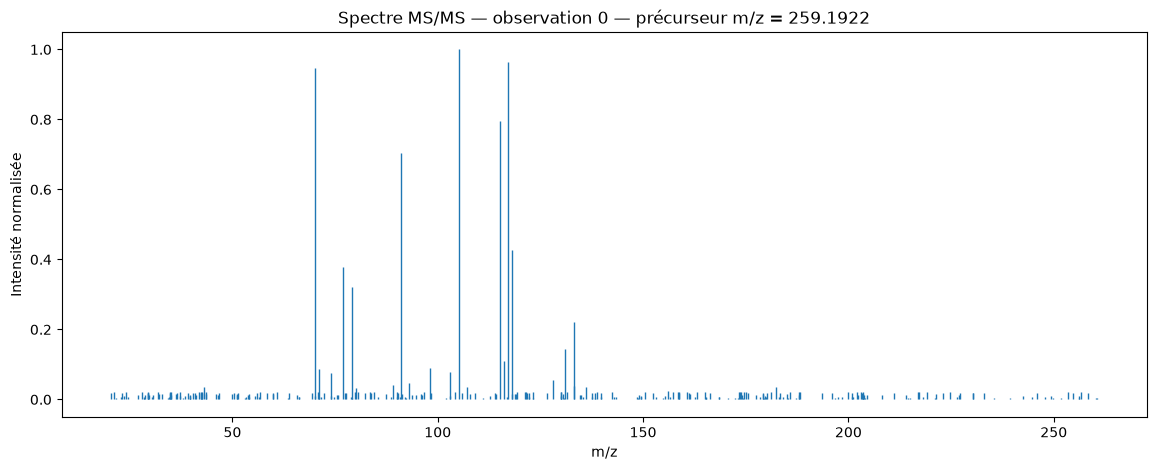

In [14]:
ROW_ID = 0
row = train.iloc[ROW_ID]

mzs = np.asarray(row["ms2_mzs"], dtype=float)
intensities = np.asarray(row["ms2_normalized_intensities"], dtype=float)

plt.figure(figsize=(14, 5))
plt.vlines(mzs, 0, intensities, linewidth=1)
plt.xlabel("m/z")
plt.ylabel("Intensité normalisée")

title = f"Spectre MS/MS — observation {ROW_ID}"
if "precursor_mz" in train.columns:
    title += f" — précurseur m/z = {row['precursor_mz']}"
plt.title(title)
plt.show()


## 10. Voir les pics les plus intenses

In [15]:
peaks = (
    pd.DataFrame({"mz": mzs, "intensity": intensities})
    .sort_values("intensity", ascending=False)
    .reset_index(drop=True)
)

display(peaks.head(20))


,mz,intensity
0,105.0704,1.000000
1,117.0704,0.963557
2,70.0412,0.946506
3,115.0551,0.794292
4,91.0551,0.703549
5,118.0765,0.428394
6,77.0387,0.379437
7,79.0553,0.322430
8,133.1006,0.221442
9,131.0843,0.143578


## 11. Afficher la molécule correspondante avec RDKit

In [16]:
%pip install rdkit

Note: you may need to restart the kernel to use updated packages.


SMILES : CCn1cnnc1CNC(C)c1ccc(C)c(C)c1


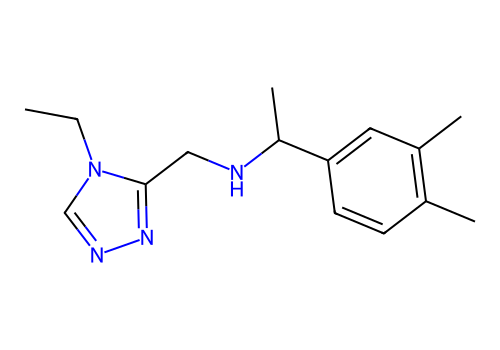

In [17]:
if "normalized_smiles" in train.columns:
    try:
        from rdkit import Chem
        from rdkit.Chem import Draw

        smiles = row["normalized_smiles"]
        print("SMILES :", smiles)
        mol = Chem.MolFromSmiles(smiles)

        if mol is not None:
            display(Draw.MolToImage(mol, size=(500, 350)))
        else:
            print("SMILES non interprétable par RDKit.")
    except ImportError:
        print("RDKit n’est pas installé dans cet environnement.")


## 12. Examiner rapidement le test

In [18]:
test_file = pq.ParquetFile(TEST_PATH)

print(f"Nombre de lignes test   : {test_file.metadata.num_rows:,}")
print(f"Nombre de colonnes test : {test_file.metadata.num_columns}")

test = test_file.read_row_group(0).to_pandas().head()
display(test)


Nombre de lignes test   : 1,213
Nombre de colonnes test : 12


,molecule_id,spectrum_id,ms2_mzs,ms2_normalized_intensities,base_peak_intensity,adduct,ionization_mode,instrument_type,precursor_mz,collision_energy_orig,collision_energy_ev,collision_energy_orig_units
0,m_005e53,s_4d19d522,"[67.0414, 73.0074, 74.0142, 74.0174, 75.0238, ...","[0.0016501163269310492, 0.0004909040749095276,...",2711324.0,[M+H]+,positive,timsTOF,375.0709,"20,40,60","[20.0, 40.0, 60.0]",eV
1,m_005e53,s_5b6e28ff,"[67.0414, 73.0074, 74.0174, 75.0236, 76.0311, ...","[0.0029581573469943693, 0.0008800418929033316,...",1512428.0,[M+H]+,positive,timsTOF,375.0709,40,[40.0],eV
2,m_005e53,s_6e514292,"[74.0142, 75.0238, 76.0313, 77.0357, 77.0398, ...","[0.0071407135863519105, 0.009720343101840298, ...",989677.0,[M+H]+,positive,timsTOF,375.0709,60,[60.0],eV
3,m_005e53,s_855ae19c,"[42.9863, 45.6701, 69.5715, 78.9191, 78.929, 7...","[0.0014297061159650516, 0.0014297061159650516,...",6295.0,[M-H]-,negative,timsTOF,373.0562,-60,[60.0],eV
4,m_006153,s_3c74e9fe,"[65.0391, 77.0385, 77.1154, 78.0479, 85.0515, ...","[0.000254435863675019, 0.0009782620275780901, ...",3191374.0,[M+H]+,positive,timsTOF,342.1569,20,[20.0],eV


## 13. Voir le format de soumission

In [19]:
sample_submission = pd.read_csv(SUBMISSION_PATH)
print("Dimensions :", sample_submission.shape)
display(sample_submission.head())


Dimensions : (400, 2)


,molecule_id,smiles
0,m_005e53,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
1,m_006153,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
2,m_00b5aa,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
3,m_01e922,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...
4,m_0259d4,CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CC...


## 14. Charger tout le train si nécessaire

Seulement si tu as assez de RAM :

```python
train_full = pd.read_parquet(TRAIN_PATH)
```

Pour l’EDA initiale, l’échantillon avec `pyarrow` est préférable.


In [20]:
print(len(train))
print(train_file.metadata.num_rows)

10000
2539608


## Passage sur le vrai dataset meta

### Visualisation de meta

In [21]:
meta = pd.read_parquet(
    TRAIN_PATH,
    columns=[
        "inchikey14",
        "normalized_smiles",
        "ingest_lib",
        "ionization_mode",
        "adduct",
        "precursor_mz",
        "instrument_type",
        "num_peaks",
        "base_peak_intensity",
        "collision_energy_ev"
    ]
)

print(meta.shape)

(2539608, 10)


In [22]:
print("Spectres :", len(meta))
print("Molécules :", meta["inchikey14"].nunique())

display(meta["ingest_lib"].value_counts())
display(meta["adduct"].value_counts(dropna=False))
display(meta["ionization_mode"].value_counts(dropna=False))

display(
    meta.groupby("inchikey14")
        .size()
        .describe()
)

Spectres : 2539608
Molécules : 275810


ingest_lib
enveda-180            1153785
pluskal_ms2            527581
riken                  347171
gnps                   220849
massbank               101727
mona                    92416
spectraverse            50933
msdial                  40765
drug_plus                2545
enveda-np-examples       1184
masaryk                   652
Name: count, dtype: int64

adduct
[M+H]+         1324585
[M-H]-          465688
[2M+Na]+        190033
[M+Na]+         178092
[2M+H]+          92041
                ...   
[M-CH3O]+            1
[2M-H5O3]+           1
[M+C2H7OS]+          1
[M+HO]+              1
[3M+K]+              1
Name: count, Length: 121, dtype: int64

ionization_mode
positive    1899640
negative     639968
Name: count, dtype: int64

count    275810.000000
mean          9.207817
std          21.069560
min           1.000000
25%           4.000000
50%           6.000000
75%           9.000000
max        1468.000000
dtype: float64

# Construction de la première validation 5folds

In [23]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


### Création des feuilles de la validation croisée

In [24]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)

meta["fold"] = -1

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(meta, groups=meta["inchikey14"])
):
    meta.loc[val_idx, "fold"] = fold

meta.head(10)

,inchikey14,normalized_smiles,ingest_lib,ionization_mode,adduct,precursor_mz,instrument_type,num_peaks,base_peak_intensity,collision_energy_ev,fold
0,AAALVYBICLMAMA,O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21,drug_plus,positive,[M+H]+,330.1237,NaN,52,NaN,None,2
1,AAKJLRGGTJKAMG,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,drug_plus,positive,[M+K]+,432.1320,NaN,28,NaN,None,2
2,AANFHDFOMFRLLR,CC1(C)CCC(C)(C)c2cc(C(O)C(O)=Nc3ccc(C(=O)O)cc3...,drug_plus,positive,[M+Na]+,422.1738,NaN,41,NaN,None,1
3,AAOVKJBEBIDNHE,CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc21,drug_plus,positive,[M+H]+,285.0789,NaN,166,NaN,None,4
4,ACFIXJIJDZMPPO,NC(=O)C1=CN(C2OC(COP(=O)(O)OP(=O)(O)OCC3OC(n4c...,drug_plus,positive,[M+H]+,746.0984,NaN,186,NaN,None,2
5,ACGDKVXYNVEAGU,N=C(N)NCCN1CCCCCCC1,drug_plus,positive,[M+H]+,199.1917,NaN,119,NaN,None,2
6,ACNHBCIZLNNLRS,CC(C)(O)C1OC2CCC3(C)C(O)(CCC4Cc5c([nH]c6ccccc5...,drug_plus,positive,[M+K]+,474.2041,NaN,200,NaN,None,0
7,ACPOUJIDANTYHO,O=C1c2ccccc2-c2n[nH]c3cccc1c23,drug_plus,positive,[M+H]+,221.0709,NaN,9,NaN,None,2
8,ACRHBAYQBXXRTO,COc1cc2c(cc1OC)CC(=O)N(CCCN(C)CC1Cc3cc(OC)c(OC...,drug_plus,positive,[M+K]+,507.2256,NaN,55,NaN,None,2
9,ACTIUHUUMQJHFO,COC1=C(OC)C(=O)C(CC=C(C)CCC=C(C)CCC=C(C)CCC=C(...,drug_plus,positive,[M+NH4]+,863.6912,NaN,200,NaN,None,1


### Vérification de la répartition des molécules dans les folds

In [25]:
for fold in range(5):
    train_keys = set(meta.loc[meta.fold != fold, "inchikey14"])
    val_keys = set(meta.loc[meta.fold == fold, "inchikey14"])

    print(f"Fold {fold} :", len(train_keys & val_keys))

check = meta.groupby("inchikey14")["fold"].nunique()

print(check.value_counts())

assert check.max() == 1

Fold 0 : 0
Fold 1 : 0
Fold 2 : 0
Fold 3 : 0
Fold 4 : 0
fold
1    275810
Name: count, dtype: int64


### Sauvergarde des feuilles

In [26]:
meta[["inchikey14", "fold"]].to_parquet(
    "casmi_folds.parquet",
    index=False
)

### Visualisation des na sur meta

In [27]:
summary = pd.DataFrame({
    "type": meta.dtypes.astype(str),
    "nb_manquants": meta.isna().sum(),
    "pct_manquants": (meta.isna().mean() * 100).round(2)
})

display(summary)


,type,nb_manquants,pct_manquants
inchikey14,str,0,0.00
normalized_smiles,str,0,0.00
ingest_lib,str,0,0.00
ionization_mode,str,0,0.00
adduct,str,0,0.00
precursor_mz,float64,0,0.00
instrument_type,str,33053,1.30
num_peaks,int64,0,0.00
base_peak_intensity,float64,1163138,45.80
collision_energy_ev,object,337443,13.29


In [28]:
fold_by_key = (
    meta[["inchikey14", "fold"]]
    .drop_duplicates("inchikey14")
    .set_index("inchikey14")["fold"]
)

fold_by_key.head()

inchikey14
AAALVYBICLMAMA    2
AAKJLRGGTJKAMG    2
AANFHDFOMFRLLR    1
AAOVKJBEBIDNHE    4
ACFIXJIJDZMPPO    2
Name: fold, dtype: int64

In [29]:
import numpy as np

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

FP_SIZE = 1024

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=FP_SIZE
)

In [30]:
def smiles_to_fp(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    fp = morgan_generator.GetFingerprint(mol)

    arr = np.zeros(FP_SIZE, dtype=np.uint8)

    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr

### Tests

In [31]:
smiles = meta.iloc[0]["normalized_smiles"]

fp = smiles_to_fp(smiles)

print(fp.shape)
print(fp)
print("Nombre de bits actifs :", fp.sum())

(1024,)
[0 0 0 ... 0 0 0]
Nombre de bits actifs : 25


## Transformations des moélcules Smiles en Fingerprint

In [32]:
molecules = (
    meta[
        ["inchikey14", "normalized_smiles"]
    ]
    .drop_duplicates("inchikey14")
    .reset_index(drop=True)
)

print(molecules.shape)

molecules["fingerprint"] = (
    molecules["normalized_smiles"]
    .apply(smiles_to_fp)
)

display(molecules.head())

print(
    molecules["fingerprint"]
    .isna()
    .sum()
)

(275810, 2)


,inchikey14,normalized_smiles,fingerprint
0,AAALVYBICLMAMA,O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,AAKJLRGGTJKAMG,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, ..."
2,AANFHDFOMFRLLR,CC1(C)CCC(C)(C)c2cc(C(O)C(O)=Nc3ccc(C(=O)O)cc3...,"[0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,AAOVKJBEBIDNHE,CN1C(=O)CN=C(c2ccccc2)c2cc(Cl)ccc21,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,ACFIXJIJDZMPPO,NC(=O)C1=CN(C2OC(COP(=O)(O)OP(=O)(O)OCC3OC(n4c...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, ..."


0


# Création d'un dictionnaire molécule local

In [33]:
fp_by_key = dict(
    zip(
        molecules["inchikey14"],
        molecules["fingerprint"]
    )
)
key = meta.iloc[0]["inchikey14"]

fp_by_key[key]

array([0, 0, 0, ..., 0, 0, 0], shape=(1024,), dtype=uint8)

# Création d'un dictionnaire de masse monoisotopique

## Fonction de calcul masse de la molécule neutre

### Test simple

### Quels individus ne correspondent pas au dictionnaire adduct ?

In [37]:
import re
from rdkit import Chem

ELECTRON_MASS = 0.000548579909065
PERIODIC_TABLE = Chem.GetPeriodicTable()


def get_atom_mass(symbol):
    """
    Retourne la masse monoisotopique de l'élément.
    """
    atomic_number = PERIODIC_TABLE.GetAtomicNumber(symbol)

    if atomic_number == 0:
        raise ValueError(f"Atome inconnu : {symbol}")

    return PERIODIC_TABLE.GetMostCommonIsotopeMass(atomic_number)


def formula_mass(formula):
    """
    Calcule la masse d'une formule chimique.

    Exemples :
    H       -> masse de H
    H2O     -> 2*H + O
    C4H11O2 -> 4*C + 11*H + 2*O
    2H2O    -> 2 * (2*H + O)
    """

    # coefficient devant toute la formule : ex. 2H2O
    match = re.fullmatch(r"(\d*)([A-Za-z0-9]+)", formula)

    if match is None:
        raise ValueError(f"Formule non reconnue : {formula}")

    global_coef = int(match.group(1)) if match.group(1) else 1
    formula_body = match.group(2)

    # Ex. C4H11O2 -> [('C','4'), ('H','11'), ('O','2')]
    elements = re.findall(r"([A-Z][a-z]?)(\d*)", formula_body)

    mass = 0.0

    for symbol, count in elements:
        count = int(count) if count else 1
        mass += get_atom_mass(symbol) * count

    return global_coef * mass


def get_neutral_mass(precursor_mz, adduct):
    """
    Calcule la masse neutre M à partir du precursor_mz et de l'adduct.

    Exemples supportés :
    [M+H]+
    [M-H]-
    [M-C4H11O2]+
    [M-H5O3]+
    [2M+Ca-H]+
    [M-2H2O+H]+
    [M-2H]2-
    """

    # ----------------------------------
    # 1. Contenu entre crochets
    # ----------------------------------

    match = re.search(r"\[(.*?)\]", adduct)

    if match is None:
        raise ValueError(f"Adduct invalide : {adduct}")

    inside = match.group(1)

    # Ex :
    # "2M+Ca-H" -> ["2M", "+Ca", "-H"]
    parts = re.findall(r"[+-]?[^+-]+", inside)

    if len(parts) == 0:
        raise ValueError(f"Adduct vide : {adduct}")

    # ----------------------------------
    # 2. Nombre de molécules M
    # ----------------------------------

    m_part = parts[0]

    m_match = re.fullmatch(r"(\d*)M", m_part)

    if m_match is None:
        raise ValueError(
            f"Premier bloc non reconnu comme M : {m_part}"
        )

    coeff_mol = (
        int(m_match.group(1))
        if m_match.group(1)
        else 1
    )

    # ----------------------------------
    # 3. Masse des ajouts / pertes
    # ----------------------------------

    relative_sum = 0.0

    for part in parts[1:]:

        if part.startswith("+"):
            sign = +1
            formula = part[1:]

        elif part.startswith("-"):
            sign = -1
            formula = part[1:]

        else:
            sign = +1
            formula = part

        relative_sum += sign * formula_mass(formula)

    # ----------------------------------
    # 4. Charge
    # ----------------------------------

    # Ex :
    # ]+   -> z = +1
    # ]-   -> z = -1
    # ]2+  -> z = +2
    # ]3-  -> z = -3

    charge_match = re.search(r"\](\d*)([+-])$", adduct)

    if charge_match is None:
        raise ValueError(
            f"Charge non reconnue : {adduct}"
        )

    charge_magnitude = (
        int(charge_match.group(1))
        if charge_match.group(1)
        else 1
    )

    charge_sign = (
        +1
        if charge_match.group(2) == "+"
        else -1
    )

    z = charge_sign * charge_magnitude

    # ----------------------------------
    # 5. Passage de m/z à masse ionique
    # ----------------------------------

    ion_mass = abs(z) * precursor_mz

    # ----------------------------------
    # 6. Masse neutre
    # ----------------------------------

    neutral_mass = (
        ion_mass
        - relative_sum
        + z * ELECTRON_MASS
    ) / coeff_mol

    return neutral_mass

### Tests rapides

In [38]:
tests = [
    "[M+H]+",
    "[M-H]-",
    "[M-C4H11O2]+",
    "[M-H5O3]+",
    "[2M+Ca-H]+",
    "[M-2H2O+H]+",
    "[M-2H]2-"
]

for adduct in tests:
    try:
        mass = get_neutral_mass(500.0, adduct)
        print(f"{adduct:20s} -> {mass:.6f}")
    except Exception as e:
        print(f"{adduct:20s} -> ERREUR : {e}")

[M+H]+               -> 498.992724
[M-H]-               -> 501.007276
[M-C4H11O2]+         -> 591.076453
[M-H5O3]+            -> 553.024418
[2M+Ca-H]+           -> 230.522891
[M-2H2O+H]+          -> 535.013853
[M-2H]2-             -> 1002.014553


#### Test sur meta sans na

In [39]:
adducts_test = (
    meta[["adduct"]]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)
adducts_test["neutral_mass_test"] = adducts_test["adduct"].apply(
    lambda adduct: get_neutral_mass(
        500.0,
        adduct
    )
)
display(adducts_test)

ValueError: Premier bloc non reconnu comme M : Cat

# Test de KNN en cross validation

In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = []

for k in range(5):
    X_train = meta.loc[meta["fold"] != k]
    X_test = meta.loc[meta["fold"] == k]

    nn = NearestNeighbors(
        n_neighbors=5,
        algorithm='auto',
        n_jobs=-1
    )

    nn.fit(X_train)

    distances, indices = nn.kneighbors(X_test)

